<a href="https://colab.research.google.com/github/hilduAgl/brain-age-eeg/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Describe the preprocessing, where did you get the code? what choices you made and why. The following code was built on the starter notebook EEG_dataloader.ipynb, only things that were changed is the file path.

In [14]:
import os
import torch
from torch.utils.data import Dataset

class EEGDataset(Dataset):
    def __init__(self, file_path, segments, segment_duration, sampling_rate, cache_size=None):
        self.file_path = file_path
        self.segments = segments
        self.segment_duration = 1.0*segment_duration
        self.sampling_rate = sampling_rate
        if cache_size is None:
            self.max_cache_size = 0
        elif cache_size == 'inf':
            self.max_cache_size = 10E9 # Number of elements (2 bytes per element)
        else:
            self.max_cache_size = cache_size # Max number of samples stored in the cache on each worker
        self.cache_size = 0
        self.file_cache = {}

    def __len__(self):
        return len(self.segments)

    def __getitem__(self, idx):
        torch_file = self.segments[idx][4]
        istart = int(self.segments[idx][0]*self.sampling_rate)
        label = self.segments[idx][3]
        n_samples = int(self.sampling_rate*self.segment_duration)

        # Caching - Store EEG in a dictionary for fast lookup
        if torch_file in self.file_cache:
            data = self.file_cache[torch_file]
        else:
            data = torch.load(os.path.join(self.file_path, 'pre_processed/' + torch_file.replace('.edf','.pt')))
            if self.cache_size + torch.numel(data) < self.max_cache_size:
                self.file_cache[torch_file] = data
                self.cache_size += torch.numel(data)
        assert(data.shape[1] >= n_samples)

        # Starting point of segment is specified by b_start
        # It is zero currently which corresponds to the start of the recording
        # NOTE: If you want to use random cropping you can implement it by modifying b_start
        b_start = self.segments[idx][2]
        istart = int(b_start*self.sampling_rate)
        data1 = data[:, istart:(istart + n_samples)] # Copy data prior to type conversion/augmentation
        assert(data1.shape[1] == n_samples) # slicing out of bounds in pytorch is silent, therefore need to check
        if data1.dtype != torch.float32:
            data1 = data1.to(torch.float32) # Pytorch operates in float32 by default

        # TODO: Add augmentation code here if you decide to use augmentation
        return data1, label, idx

    def clear_cache():
        self.file_cache.clear()
        self.cache_size = 0
import os
from pathlib import Path
import torch

RESAMPLING_RATE = 64
SEGMENT_DURATION = 8 # TODO: Decide on appropriate block size for your model

BATCH_SIZE = 64 # TODO: Modify as needed

path = Path('/content/drive/MyDrive/BrainAge/data')
pre_processed_path = path / Path('pre_processed')

train_segments = torch.load(path / 'segments_h1k_train.pt')
val_segments = torch.load(path / 'segments_h1k_val.pt')
test_segments = torch.load(path / 'segments_h1k_test.pt')
from torch.utils.data import DataLoader

train_dataset = EEGDataset(path, train_segments,
                           segment_duration=SEGMENT_DURATION,
                           sampling_rate=RESAMPLING_RATE,
                           cache_size=2E9)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, num_workers = 0)

it = iter(train_loader)
data, label, _ = next(it)

data.shape, len(label)

(torch.Size([64, 20, 512]), 64)

The network was designed with figure 3 from the final project pdf. Rather than computing the features manually, they were learned from stacking convolutional, max-pool, and ReLU layers, similar to what was done in homework assignment 8. The number of filters was initially 32 and then progressively doubled as it passes through the convolutional layers.


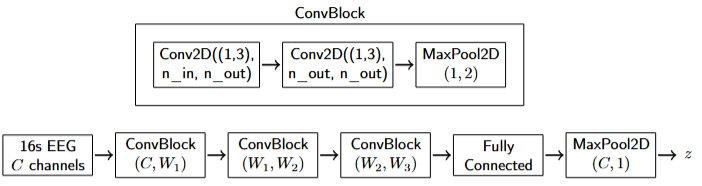 (Figure 3)

In [15]:
import torch
import torch.nn as nn

class ConvBlock(nn.Module):

  def __init__(self, in_channels, out_channels):
    super(ConvBlock, self).__init__()
    self.block = nn.Sequential(
        nn.Conv2d(
            in_channels, out_channels, kernel_size=(1, 3), padding=(0, 1)
        ),
        nn.ReLU(),
        nn.Conv2d(
            out_channels, out_channels, kernel_size=(1, 3), padding=(0, 1)
        ),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=(1, 2)),
    )

  def forward(self, x):
    return self.block(x)


class BrainAgeCNN(nn.Module):

  def __init__(self, in_channels=20):
    super(BrainAgeCNN, self).__init__()

    self.conv1 = ConvBlock(1, 32)
    self.conv2 = ConvBlock(32, 64)
    self.conv3 = ConvBlock(64, 128)

    self.fc = nn.Sequential(
        nn.Flatten(),
        nn.Linear(128 * in_channels * (512 // 8), 128),
        nn.ReLU(),
        nn.Linear(128, 1),
    )

  def forward(self, x):
    if x.dim() == 3:
      x = x.unsqueeze(1)

    x = self.conv1(x)
    x = self.conv2(x)
    x = self.conv3(x)
    x = self.fc(x)
    return x.squeeze(-1)

model = BrainAgeCNN()
sample_batch, labels, _ = next(iter(train_loader))
output = model(sample_batch)
print("Model output shape:", output.shape)

Model output shape: torch.Size([64])


The model is optimized using Stochastic Gradient Descent with momentum 0.9 and a conservative learning rate of 0.0001 paired with Mean Squared Error to ensure stable weight updates without exploding gradients which was a problem to begin with. Trained across 10 epochs on the full dataset, the average loss steadily decreases from an initial 156.55 down to about 17.31.

In [16]:
import torch
import torch.nn as nn
import torch.optim as optim

model = BrainAgeCNN()
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

model.train()
epochs = 10

for epoch in range(epochs):
  epoch_loss = 0.0
  for batch_idx, (data, labels, _) in enumerate(train_loader):
    optimizer.zero_grad()
    predictions = model(data)
    loss = criterion(predictions, labels.float())

    if torch.isnan(loss) or torch.isinf(loss):
      print(f"Warning: Loss became {loss.item()} at epoch {epoch+1}")
      break

    loss.backward()
    optimizer.step()

    epoch_loss += loss.item()

  print(
      f"Epoch {epoch+1}/{epochs} | Avg Loss:"
      f" {epoch_loss / len(small_train_loader):.4f}"
  )

Epoch 1/10 | Avg Loss: 156.5479
Epoch 2/10 | Avg Loss: 143.5481
Epoch 3/10 | Avg Loss: 99.7432
Epoch 4/10 | Avg Loss: 66.5096
Epoch 5/10 | Avg Loss: 33.0491
Epoch 6/10 | Avg Loss: 20.0488
Epoch 7/10 | Avg Loss: 22.4456
Epoch 8/10 | Avg Loss: 17.2044
Epoch 9/10 | Avg Loss: 15.8559
Epoch 10/10 | Avg Loss: 17.3057


Once trained, the model is evaluated on the independent validation set to monitor performance using Mean Absolute Error and Root Mean Squared Error in years. Making sure that it performs effectively on unseen data.

In [17]:
val_segments = torch.load(os.path.join(path, "segments_h1k_val.pt"))

val_dataset = EEGDataset(
    path,
    val_segments,
    segment_duration=SEGMENT_DURATION,
    sampling_rate=RESAMPLING_RATE,
    cache_size=2e9,
)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model.eval()

val_loss = 0.0
absolute_errors = []

with torch.no_grad():
  for data, labels, _ in val_loader:

    predictions = model(data)

    loss = criterion(predictions, labels.float())
    val_loss += loss.item()

    batch_ae = torch.abs(predictions - labels.float())
    absolute_errors.extend(batch_ae.tolist())

avg_val_loss = val_loss / len(val_loader)
mae = sum(absolute_errors) / len(absolute_errors)
rmse = avg_val_loss**0.5

print(f"Validation Results:")
print(f"MSE Loss: {avg_val_loss:.4f}")
print(f"MAE (Years): {mae:.4f}")
print(f"RMSE (Years): {rmse:.4f}")

Validation Results:
MSE Loss: 6.1673
MAE (Years): 1.8322
RMSE (Years): 2.4834


Then the model is evaluated on the entirely unseen test split. This results in a final Test MAE of 1.8703 years and a Test RMSE of 2.4055 years, confirming how effective self learning CNN´s are.

In [18]:
test_segments = torch.load(os.path.join(path, "segments_h1k_test.pt"))

test_dataset = EEGDataset(
    path,
    test_segments,
    segment_duration=SEGMENT_DURATION,
    sampling_rate=RESAMPLING_RATE,
    cache_size=2e9,
)

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

model.eval()
test_loss = 0.0
absolute_errors = []

with torch.no_grad():
  for data, labels, _ in test_loader:
    predictions = model(data)
    loss = criterion(predictions, labels.float())
    test_loss += loss.item()

    batch_ae = torch.abs(predictions - labels.float())
    absolute_errors.extend(batch_ae.tolist())

avg_test_loss = test_loss / len(test_loader)
test_mae = sum(absolute_errors) / len(absolute_errors)
test_rmse = avg_test_loss**0.5

print(f"Final Test Results:")
print(f"Test MAE (Years): {test_mae:.4f}")
print(f"Test RMSE (Years): {test_rmse:.4f}")

Final Test Results:
Test MAE (Years): 1.8703
Test RMSE (Years): 2.4055


Summary: By replacing manual feature extraction with a multi layer convolutional architecture, the custom BrainAgeCNN successfully learned temporal representations from raw EEG segments. Across training, validation, and testing, the model maintained a tight predictive error margin of under two years, demonstrating a complete, effective model.

